In [ ]:
from bbresults import BackboneScenarioAnalysis
from bbresults import BackboneResult
from functools import partial
import numpy as np
from gams import GamsWorkspace
import pandas as pd
import os
from pathlib import Path
import re
import subprocess as sp
from io import StringIO
from io import StringIO
from matplotlib.pyplot import get_cmap
from matplotlib.colors import to_hex
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import pickle as pickle
from scipy.stats import gaussian_kde
import seaborn as sns
import plotly.io as pio   
pio.kaleido.scope.mathjax = None

In [ ]:
###Figures 4 and 5

In [ ]:
#load results from your path
res=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2")
res_invest=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2/invest")

In [ ]:
###Prices and generation time series
df_moments=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):     
    
    #electricity prices    
    r_balanceMarginal = r.r_balanceMarginal()
    r_balanceMarginal=r_balanceMarginal.rename(columns={"Val": "price"})
    r_balanceMarginal = r_balanceMarginal[r_balanceMarginal["grid"]=="elec"]
    r_balanceMarginal["price"]=r_balanceMarginal["price"]*-1
    r_balanceMarginal= r_balanceMarginal.drop(columns=["grid","f"])

    #generation
    r_gen=r.r_gen()
    r_gen1=r_gen[r_gen['unit'].apply(lambda x: 1 if any(i in x for i in ["Wind Onshore New 1"]) else 0)==1]
    r_gen1=r_gen1.rename(columns={"Val": "gen_t"})
    r_gen1= r_gen1[["unit","node","t","gen_t"]]

    r_gen2=r_gen[r_gen['unit'].apply(lambda x:1 if any(i in x for i in ["Wind Onshore New 2"]) else 0)==1]
    r_gen2=r_gen2.rename(columns={"Val": "gen_t"})
    r_gen2= r_gen2[["unit","node","t","gen_t"]]

    t_full = pd.Series(range(1, 8761), name="t")

    unit_node_pairs1 = r_gen1[["unit", "node"]].drop_duplicates()

    full_index1 = (
    unit_node_pairs1.assign(key=1)
    .merge(t_full.to_frame().assign(key=1), on="key")
    .drop("key", axis=1)
    )

    r_gen1_full = full_index1.merge(r_gen1, on=["unit", "node", "t"], how="left") 
    r_gen1_full["gen_t"] = r_gen1_full["gen_t"].fillna(0)

    unit_node_pairs2 = r_gen2[["unit", "node"]].drop_duplicates()

    full_index2 = (
    unit_node_pairs2.assign(key=1)
    .merge(t_full.to_frame().assign(key=1), on="key")
    .drop("key", axis=1)
    )

    r_gen2_full = full_index2.merge(r_gen2, on=["unit", "node", "t"], how="left")
    r_gen2_full["gen_t"] = r_gen2_full["gen_t"].fillna(0)
    
    #merge everything
    df_moment=r_gen1_full.merge(r_balanceMarginal,on=["t","node"],how="left")
    df_moment2=r_gen2_full.merge(r_balanceMarginal,on=["t","node"],how="left")
    df_moment=pd.concat([df_moment,df_moment2])
    df_moment["scen"]=str(s)
    df_moments=pd.concat([df_moments,df_moment])

In [ ]:
#store prices and generation time series
df_moments.to_pickle("moments")

In [ ]:
###Select a bidding zone
df_mo=df_moments
nodes=["ES elec","FR elec","DK elec"]
df_mo=df_mo[df_mo['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==1]

##alterantive: choose BZ with both wind profiles
#list=["AT elec","CZ elec","SE elec","IE elec","BT elec","PT elec","IT elec","BK elec"]
#df_mo=df_mo[df_mo['node'].apply(lambda x: 1 if any(i in x for i in list) else 0)==0]

#only new units
df_mo=df_mo[df_mo['unit'].apply(lambda x: 1 if any(i in x for i in ["New"]) else 0)==1]

##alternative: drop 2010
#df_mo=df_mo[df_mo['scen'].apply(lambda x: 1 if any(i in x for i in ["2010"]) else 0)==0]

In [5]:
###data adjustments
#add demand response price as max price
res1=res.bb_results[0]
p_gnu_io=res1.param_as_df("p_gnu_io")
unitUnittype=res1.set_as_df("unitUnittype")
p_gnu_io=p_gnu_io.merge(unitUnittype,on="unit")
p_gnu_io["vomCosts"]=p_gnu_io[p_gnu_io['param_gnu']=='vomCosts']["value"]
dsr=p_gnu_io[p_gnu_io["unittype"]=="dsr"]
dsr=dsr[["node","vomCosts"]]
dsr=dsr.rename(columns={"vomCosts": "maxprice"})
maxprice = dsr['maxprice'].max()
df_mo.loc[
    (df_mo["price"] > maxprice) 
 #   & (df_mo["price"] < 3999)
    ,
    "price"
] = maxprice

In [ ]:
#retrieve capacities
p_gnu_io=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):     
    p_gnu=r.param_as_df("p_gnu_io")
    p_gnu=p_gnu[p_gnu['input_output']=='output']
    p_gnu["capacity"]=p_gnu[p_gnu['param_gnu']=='capacity']["value"]
    p_gnu["fomCosts"]=p_gnu[p_gnu['param_gnu']=='fomCosts']["value"]
    p_gnu["vomCosts"]=p_gnu[p_gnu['param_gnu']=='vomCosts']["value"]
    p_gnu["invCosts"]=p_gnu[p_gnu['param_gnu']=='invCosts']["value"]
    p_gnu["annuityFactor"]=p_gnu[p_gnu['param_gnu']=='annuityFactor']["value"]
    p_gnu=p_gnu.groupby(['node','grid','unit']).sum().reset_index()
    p_gnu=p_gnu[["node","grid","unit","vomCosts","fomCosts","invCosts","annuityFactor","capacity"]]
    p_gnu["scen"]=str(s)
    p_gnu_io=pd.concat([p_gnu_io,p_gnu])

In [ ]:
#get w, f and p and their products
df_Q=df_mo.drop_duplicates(["unit","node","scen"]).drop(columns=["t","price","gen_t"])
df_Q=df_Q.merge(p_gnu_io,on=["node","unit","scen"])
df_Q_I=df_Q.groupby(["node","scen"])["capacity"].sum().reset_index().rename(columns={'capacity': 'capacity_node'})
df_Q=df_Q.merge(df_Q_I,on=["node","scen"])
df_Q["Q_Share"]=df_Q["capacity"]/df_Q["capacity_node"]
df_Q=df_Q.drop_duplicates(["unit","node","scen"])
df_Q=df_Q[["scen","unit","node","Q_Share","capacity","capacity_node"]]
df_spc=df_mo.merge(df_Q,on=["unit","node","scen"])
df_spc["cf"]=(df_spc["gen_t"]/df_spc["capacity"])
df_spc["fp"]=(df_spc["price"]*df_spc["cf"])
df_spc["wfp"]=(df_spc["fp"]*df_spc["Q_Share"])
df_spc=df_spc[["unit","node","scen","fp","t","cf","wfp"]]
#sum f and fp over T multiply with w
df_spc=df_spc.groupby(["unit","node","scen"]).sum().reset_index().drop(columns="t")

In [10]:
#sum sum(f), sum(fp) and #sum(wfp) over i \in I in a node
df_node_rev=df_spc.groupby(["node","scen"])[["cf","fp","wfp"]].sum().reset_index().rename(columns={"cf":"cf_node","fp":"fp_node","wfp":"wfp_node"})
df_spc=df_spc.merge(df_node_rev,on=["node","scen"])

In [ ]:
#strike price components
df_spc=df_spc.merge(p_gnu_io,on=["node","unit","scen"])
df_spc["lcoe"]=(df_spc["vomCosts"]+(df_spc["fomCosts"]+df_spc["invCosts"]*df_spc["annuityFactor"])/df_spc["cf"])
df_spc["v"]=(df_spc["fp_node"]/df_spc["cf_node"])
df_spc["v_i"]=(df_spc["fp"]/df_spc["cf"])
df_spc["markup"]=df_spc["v"]-df_spc["v_i"]
df_spc["cost_rec"]=(df_spc["v_i"]/df_spc["lcoe"]*100)
df_spc["ann_cost_mw"]=(df_spc["vomCosts"]*df_spc["cf"]+df_spc["fomCosts"]+df_spc["invCosts"]*df_spc["annuityFactor"])/1000
df_spc["r"]=df_spc["wfp_node"]/1000
df_spc["r_i"]=df_spc["fp"]/1000
df_spc["markup_2"]=df_spc["r"]-df_spc["r_i"]
df_spc["cost_rec2"]=df_spc["r_i"]/df_spc["ann_cost_mw"]

In [ ]:
#rename & colors
df_spc["Profile"]=df_spc["unit"].map(lambda x: str(x)[16:])
df_spc["Profile"] = df_spc["Profile"].str.replace(r'\bNew 1\b', 'High FLH', regex=True)
df_spc["Profile"] = df_spc["Profile"].str.replace(r'\bNew 2\b', 'High MV', regex=True)
df_spc["node"]=df_spc["node"].map(lambda x: str(x)[:2])
palette = {
    "FR": "purple",  
    "DK": "grey",  
    "ES": "gold",  
     'Wind Onshore High FLH':'grey', 'Wind Onshore High MV':'lightgrey',
          'High FLH':'grey', 'High MV':'lightgrey',
           'ES High FLH':'grey', 'ES High MV':'lightgrey',
            'DK High FLH':'grey', 'DK High MV':'lightgrey',
        'FR High FLH':'grey', 'FR High MV':'lightgrey', 'Reference':'dodgerblue'

}

In [ ]:
###Figure 4a
value_vars = ['lcoe','v_i','v']
f_long = df_spc.melt(
    id_vars=['node', 'scen','Profile'],         
    value_vars=value_vars,            
    var_name='component',             
    value_name='value'                
)

# Extract unique v per node & scen
v_df = df_long[df_long['component']=='v'][['scen','node','value']].drop_duplicates()

# Select v_i rows
vi_df = df_long[df_long['component']=='v_i'].copy()

# Create new row for v added to v_i
v_for_vi = vi_df.copy()
v_for_vi['component'] = 'v_i'          # new component name
v_for_vi['Profile'] = 'Reference'                   # assign a new hue category

# Merge the v values per node
v_for_vi = v_for_vi.merge(v_df, on=['node','scen'], how='left', suffixes=('','_v'))
v_for_vi['value'] = v_for_vi['value_v']
v_for_vi.drop(columns=['value_v'], inplace=True)

# Combine with original data
df_long = pd.concat([df_long, v_for_vi], ignore_index=True)
df_long = df_long[df_long["component"]!="v"]
df_long["component"]=df_long["component"].replace({'lcoe': 'LCOE',"v_i":"Market Value"})

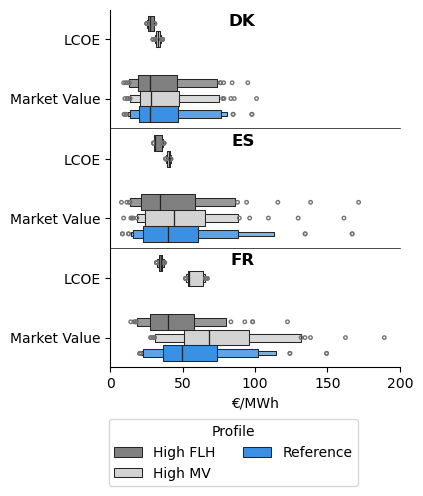

In [ ]:
g = sns.catplot(
    data=df_long,
    x="value",
    y="component",
    hue="Profile",
    row="node",      
    kind="boxen",
    sharex=True,
    height=1.5,        
    aspect=3.1  ,
    palette=palette,
    flier_kws = dict(
    marker='.',        
    linewidth=1
)
)
g.set_titles(row_template="")
for ax in g.axes.flatten()[:-1]:  
    ax.set_xlabel("")
    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    ax.spines['bottom'].set_linewidth(0.5)
for ax, node in zip(g.axes.flatten(), df_long['node'].unique()):
    ax.text(
        0.5, 0.9,  # slightly to the left of y-axis
        node,
        ha='right', va='center', fontsize=12, 
        fontweight='bold',
        transform=ax.transAxes
    )
g.set_ylabels("")
g.set_xlabels("€/MWh")
ax.set_xticks(np.arange(0, 201, 50))
ax.set_xlim(0,200)


for ax in g.axes.flatten():
    labels = [item.get_text() for item in ax.get_yticklabels()]


g._legend.remove()  
g.fig.legend(
    title="Profile",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),  
    ncol=2,

)

g.fig.subplots_adjust(hspace=0.01) 

In [ ]:
###Figure 4b
value_vars = ['ann_cost_mw','r_i','r']
#,'cf']
    #'cost_rec']
#'r_i']
#'markup','v',
df_long = df_spc.melt(
    id_vars=['node', 'scen','Profile'],         
    value_vars=value_vars,            
    var_name='component',             
    value_name='value'                
)

# Extract unique v per node
v_df = df_long[df_long['component']=='r'][['node','value','scen']].drop_duplicates()

# Select r_i rows
vi_df = df_long[df_long['component']=='r_i'].copy()

# Create new row for v added to r_i
v_for_vi = vi_df.copy()
v_for_vi['component'] = 'r_i'          # new component name
v_for_vi['Profile'] = 'Reference'                   # assign a new hue category

# Merge the v values per node
v_for_vi = v_for_vi.merge(v_df, on=['scen','node'], how='left', suffixes=('','_v'))
v_for_vi['value'] = v_for_vi['value_v']
v_for_vi.drop(columns=['value_v'], inplace=True)

# Combine with original data
df_long = pd.concat([df_long, v_for_vi], ignore_index=True)
df_long = df_long[df_long["component"]!="r"]
df_long["component"]=df_long["component"].replace({'ann_cost_mw': 'Costs per capacity',"r_i":"Revenues per capacity"})

C:\Users\silke\AppData\Local\Temp\ipykernel_8872\3902809406.py:38: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\silke\AppData\Local\Temp\ipykernel_8872\3902809406.py:38: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\silke\AppData\Local\Temp\ipykernel_8872\3902809406.py:38: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



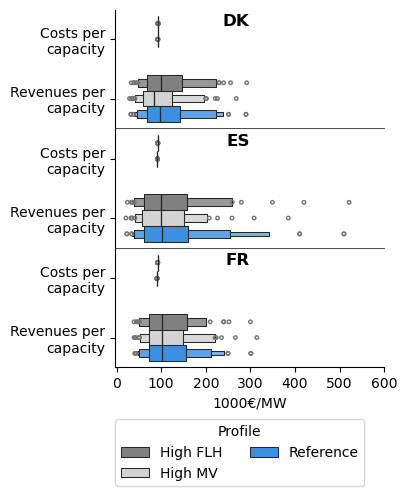

In [ ]:
g = sns.catplot(
    data=df_long,
    x="value",
    y="component",
    hue="Profile",
    row="node",      # creates a subplot per node
    kind="boxen",
    sharex=True,
    height=1.5,        # height of each subplot (default ~5)
    aspect=3.5  ,
    palette=palette,
    flier_kws = dict(
    marker='.',        
    linewidth=1
))
g.set_titles(row_template="")# Remove x-axis labels/ticks for all rows except the bottom
for ax in g.axes.flatten()[:-1]:  # all except the last row
    ax.set_xlabel("")
    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    ax.spines['bottom'].set_linewidth(0.5)
for ax, node in zip(g.axes.flatten(), df_long['node'].unique()):
    ax.text(
        0.5, 0.9,  # slightly to the left of y-axis
        node,
        ha='right', va='center', fontsize=12, 
        fontweight='bold',
        transform=ax.transAxes
    )
g.set_ylabels("")
g.set_xlabels("1000€/MW")
ax.set_xticks(np.arange(0, 601, 100))

import textwrap

for ax in g.axes.flatten():
    labels = [item.get_text() for item in ax.get_yticklabels()]
    new_labels = [ "\n".join(textwrap.wrap(l, width=12)) for l in labels ]  # wrap at ~10 chars
    ax.set_yticklabels(new_labels)
g._legend.remove()  # remove default legend
g.fig.legend(
    title="Profile",
    loc="lower center",
    bbox_to_anchor=(0.58, -0.15),  # adjust vertical spacing
    ncol=2,
    #frameon=False
)


# Reduce vertical space between facets
g.fig.subplots_adjust(hspace=0.01)  # smaller number = rows closer

In [24]:
###Calculate Cov(f_t,i,n,s;p_t,n,s) and E(f_t,i,n,s) and E(p_t,n,s) 
df_mo2=df_mo.merge(p_gnu_io,on=["unit","node","scen"])
#sum f and fp over T multiply with w
df_mo2["cf"]=(df_mo2["gen_t"]/df_mo2["capacity"])
df_pivot = df_mo2.pivot_table(index=['t', 'unit','scen','node'], values=['cf','price']).reset_index()
df_cov = df_pivot.groupby(['t', 'unit', 'node']).apply(lambda x: x[['cf', 'price']].cov().iloc[0, 1]).reset_index(name='Cov(f,p)')

C:\Users\silke\AppData\Local\Temp\ipykernel_15540\1914889026.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_cov = df_pivot.groupby(['t', 'unit', 'node']).apply(lambda x: x[['cf', 'price']].cov().iloc[0, 1]).reset_index(name='Cov(f,p)')


In [ ]:
###Calculate Cov(w_i,n,s; f_t,i,n,s p_t,n,s), E(f_t,i,n,s) and E(p_t,n,s) 
df_pivot['fp']=df_pivot['cf']*df_pivot['price']
df_f_mean=df_pivot.groupby(['unit', 'node','t'])['cf'].mean().reset_index(name='E(f)')
df_f_var=df_pivot.groupby(['unit', 'node','t'])['cf'].var().reset_index(name='Var(f)')
df_p_mean=df_pivot.drop_duplicates(["unit","node","scen"])
df_p_mean=df_pivot.groupby(['t', 'node'])['price'].mean().reset_index(name='E(p)')
df_fp_mean=df_pivot.groupby(['t', 'node','unit'])['fp'].mean().reset_index(name='E(fp)')
df_cov_fpf = df_pivot.groupby(['t', 'unit', 'node']).apply(lambda x: x[['fp', 'cf']].cov().iloc[0, 1]).reset_index(name='Cov(fp,f)')

df_Q=df_mo2.drop_duplicates(["unit","node","scen"]).drop(columns=["t","price","cf","gen_t"])
df_Q_I=df_Q.groupby(["node","scen"])["capacity"].sum().reset_index().rename(columns={'capacity': 'capacity_node'})
df_Q=df_Q.merge(df_Q_I,on=["node","scen"])
df_Q["Q_Share"]=df_Q["capacity"]/df_Q["capacity_node"]

#Cov(w,fp)
df_cov2=df_pivot.merge(df_Q,on=["node","unit","scen"],how="left")
df_cov2["cfp"]=df_cov2["cf"]*df_cov2["price"]
df_cov2=df_cov2.groupby(['t', 'unit', 'node']).apply(lambda x: x[['Q_Share', 'cfp']].cov().iloc[0, 1]).reset_index(name='Cov(w,fp)').round(5)

#E(w)
df_w_mean=df_Q.groupby(["node","unit"])["Q_Share"].mean().reset_index(name='E(w)')

C:\Users\silke\AppData\Local\Temp\ipykernel_15540\2635448789.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_cov_fpf = df_pivot.groupby(['t', 'unit', 'node']).apply(lambda x: x[['fp', 'cf']].cov().iloc[0, 1]).reset_index(name='Cov(fp,f)')


In [ ]:
#extract cost data
df_Q=df_Q.drop_duplicates(["unit","node"])
df_Q=df_Q[["unit","node","fomCosts","vomCosts","invCosts","annuityFactor"]]

In [ ]:
#,erge everything
df_mom=df_cov.merge(df_f_mean,on=["t","unit","node"])
df_mom=df_mom.merge(df_p_mean,on=["t","node"])
df_mom=df_mom.merge(df_cov2,on=["t","unit","node"])
df_mom=df_mom.merge(df_f_var,on=["t","unit","node"],how="left")
df_mom=df_mom.merge(df_cov_fpf,on=["t","unit","node"],how="left")
df_mom=df_mom.merge(df_w_mean,on=["unit","node"],how="left")

In [31]:
#calculate required expected values
df_mom["E(fp)_test"]=df_mom["E(f)"]*df_mom["E(p)"]
df_mom["E(fp)"]=df_mom["E(f)"]*df_mom["E(p)"]+df_mom["Cov(f,p)"]
df_mom["E(wfp)"]=df_mom["E(w)"]*df_mom["E(p)"]*df_mom["E(f)"]+df_mom["E(w)"]*df_mom["Cov(f,p)"]+df_mom["Cov(w,fp)"]


In [32]:
#Sum all over t
df_mom_T = df_mom.groupby(['unit','node']).sum().reset_index().drop(columns=["Cov(w,fp)","E(w)","E(p)","Cov(f,p)","t"])

In [33]:
#Sum all over i
df_mom_I = df_mom_T.groupby(['node']).sum().reset_index().rename(columns={"E(f)":"E(f)_I","E(fp)":"E(fp)_I","E(wfp)":"E(wfp)_I"})
df_mom_I=df_mom_I.drop(columns="unit")
#merge both and with cost data
df_mom_compl=df_mom_T.merge(df_mom_I,on=["node"],how="left")
df_mom_compl=df_mom_compl.merge(df_Q,on=["unit","node"])

In [34]:
#dataframe for strike prices under uncertainty
df_mom_compl["lcoe"]=df_mom_compl["vomCosts"]+(df_mom_compl["fomCosts"]+df_mom_compl["annuityFactor"]*df_mom_compl["invCosts"])/df_mom_compl["E(f)"]
df_mom_compl["ann_cost_mw"]=df_mom_compl["E(f)"]*df_mom_compl["vomCosts"]+df_mom_compl["fomCosts"]+df_mom_compl["annuityFactor"]*df_mom_compl["invCosts"]

In [ ]:
#calculate strike price for each CfD type
df_sp1=df_mom_compl.copy()
df_sp1["type"]="Basic CfD"
df_sp1["strikeprice"]=df_sp1["lcoe"]

df_sp2=df_mom_compl.copy()
df_sp2["type"]="2way CfD"
df_sp2["strikeprice"]=df_sp2["lcoe"]  + (df_sp2["E(fp)_I"])/df_sp2["E(f)_I"]- (df_sp2["E(fp)"]/df_sp2["E(f)"])

df_sp3=df_mom_compl.copy()
df_sp3["type"]="Financial CfD"
df_sp3["strikeprice"]=df_sp3["ann_cost_mw"] + df_sp3["E(wfp)_I"] - df_sp3["E(fp)"]

df_sp12=pd.concat([df_sp1,df_sp2])
df_sp30=df_sp3

df_sp1=df_sp1[["unit","node","type","strikeprice"]]
df_sp2=df_sp2[["unit","node","type","strikeprice"]]
df_sp3=df_sp3[["unit","node","type","strikeprice"]]
df_sp=pd.concat([df_sp1,df_sp2,df_sp3])

#save strike prices 
df_sp.to_pickle("strikeprice")

In [ ]:
#ranaming and rearranging dataframes
df_plot=df_sp12
df_plot["node"]=df_plot['node'].map(lambda x: str(x)[:-5])
df_plot["unit"]=df_plot["unit"].map(lambda x: str(x)[3:])
df_plot["unit"][df_plot["unit"]=="Wind Onshore New 1"]="High FLH"
df_plot["unit"][df_plot["unit"]=="Wind Onshore New 2"]="High MV"
df_plot=df_plot[df_plot["unit"]!="Wind Onshore"]
df_plot=df_plot.sort_values("node")
df_plot["sorter"]="b"
df_plot["sorter"][df_plot["type"]=="Basic CfD"]="a"
df_plot=df_plot.sort_values(["sorter","type","unit"])

df_plot2=df_sp30
df_plot2["node"]=df_plot2['node'].map(lambda x: str(x)[:-5])
df_plot2["unit"]=df_plot2["unit"].map(lambda x: str(x)[3:])
df_plot2["unit"][df_plot2["unit"]=="Wind Onshore New 1"]="High FLH"
df_plot2["unit"][df_plot2["unit"]=="Wind Onshore New 2"]="High MV"
df_plot2=df_plot2[df_plot2["unit"]!="Wind Onshore"]
df_plot2=df_plot2.sort_values("node")

df_plot["markup"]=np.where(df_plot["strikeprice"]>=df_plot["lcoe"],df_plot["strikeprice"],0)
df_plot["markdown"]=np.where(df_plot["strikeprice"]<df_plot["lcoe"],df_plot["lcoe"],0)
df_plot["lcoe"]=np.where(df_plot["strikeprice"]>=df_plot["lcoe"],df_plot["lcoe"],df_plot["strikeprice"])

df_plot2["markup"]=np.where(df_plot2["strikeprice"]>=df_plot2["ann_cost_mw"],df_plot2["strikeprice"],0)
df_plot2["markdown"]=np.where(df_plot2["strikeprice"]<df_plot2["ann_cost_mw"],df_plot2["ann_cost_mw"],0)
df_plot2["ann_cost_mw"]=np.where(df_plot2["strikeprice"]>=df_plot2["ann_cost_mw"],df_plot2["ann_cost_mw"],df_plot2["strikeprice"])

#choose bidding zones
nodes=["ES","FR","DK"]
df_plot=df_plot[df_plot['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==1]
df_plot2=df_plot2[df_plot2['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==1]
df_plot2=df_plot2.sort_values(["unit","node"])
df_plot=df_plot.sort_values(["unit","node"])

#for x axis
df_plot["scen"]=df_plot["node"]
df_plot2["scen"]=df_plot2["node"]

C:\Users\silke\AppData\Local\Temp\ipykernel_15540\628207919.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_plot["unit"][df_plot["unit"]=="Wind Onshore New 1"]="High FLH"
C:\Users\silke\AppData\Local\Temp\ipykernel_15540\628207919.py:

In [ ]:
###Figure 5
fig = make_subplots(specs=[[{"secondary_y": True}]])

co1=["firebrick", "lightcoral"]
co2=["darkblue", "royalblue"]
co3=["grey", "lightgrey"]
co4=["black", "black"]
a=0.4
for u, c1, c2, c3, c4 in zip(df_plot.unit.unique(),co1,co2,co3,co4):

        df=df_plot[df_plot.unit==str(u)] 
        fig.add_trace(go.Bar(x=[df.scen,df.type],width=a,
        y=df.markup,name="Markup",offsetgroup=str(u),legendgroup=str(u),legendgrouptitle_text=str(u)
        ,marker_color=c2))

        fig.add_trace(go.Bar(x=[df.scen,df.type],width=a,
        y=df.markdown,name="Markdown",offsetgroup=str(u),legendgroup=str(u),legendgrouptitle_text=str(u)
        ,marker_color=c1,marker_pattern_shape="/"))


        fig.add_trace(go.Bar(x=[df.scen,df.type],width=a,
        y=df.lcoe,name="Costs",offsetgroup=str(u),legendgroup=str(u),legendgrouptitle_text=str(u)
        ,marker_color=c3))

        fig.add_trace(go.Scatter(x=[df.scen,df.type],
        y=df.strikeprice,name="Strike Price",mode="markers",
        marker_symbol="cross-thin-open", offsetgroup=str(u),
        marker_color=c4))

for u, c1, c2, c3, c4 in zip(df_plot2.unit.unique(),co1,co2,co3,co4):

        df=df_plot2[df_plot2.unit==str(u)] 

        fig.add_trace(go.Bar(x=[df.scen,df.type],width=a,showlegend=False,
        y=df.markup/1000,name="Markup",offsetgroup=str(u),legendgroup=str(u),legendgrouptitle_text=str(u)
        ,marker_color=c2),secondary_y=True)

        fig.add_trace(go.Bar(x=[df.scen,df.type],width=a,showlegend=False,
        y=df.markdown/1000,name="Markdown",offsetgroup=str(u),legendgroup=str(u),legendgrouptitle_text=str(u)
        ,marker_color=c1,marker_pattern_shape="/"),secondary_y=True)

        fig.add_trace(go.Bar(x=[df.scen,df.type],width=a,showlegend=False,
        y=df.ann_cost_mw/1000,name="Costs",offsetgroup=str(u),legendgroup=str(u),legendgrouptitle_text=str(u)
        ,marker_color=c3),secondary_y=True)

        fig.add_trace(go.Scatter(x=[df.scen,df.type],
        y=df.strikeprice/1000,name="Strike Price",mode="markers",showlegend=False,
        marker_symbol="cross-thin-open", offsetgroup=str(u),
        marker_color=c4),secondary_y=True)

fig.update_layout(height=450,width=800,scattermode="group",
        plot_bgcolor='rgba(0,0,0,0)',font=dict(
        family="Open Sans",
        size=14,
        color="black"
    ),legend=dict(x=1.05, font=dict(  # Set font properties
            size=14)), 
            margin=dict(t=20)
            )# S))
fig.update_yaxes(linecolor="black",dtick=10,title="€/MWh",title_standoff = 0.5,ticks="outside",secondary_y=False,range=[0,60])
fig.update_yaxes(linecolor="black",dtick=20,title="1000€/MW",title_standoff = 2,ticks="outside",secondary_y=True,range=[0,120], color="blue")
fig.update_xaxes(linecolor="black",tickangle=270)

fig.show()